## Harbour and offshore repeated operations (Flag 19)

### Dataset Overview
Forty repeated fishing voyages and twelve ferry movements near a west-Jutland harbour, including twelve synchronized fishing–ferry encounter voyages.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Investigate the repeated operating patterns of vessels travelling between a harbour and nearby offshore areas.

Role: Maritime traffic analyst


Category: harbour and offshore repeated operations

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Who generates the repeated offshore activity?

#### Analysis action

Map the same vessel repeatedly following a similar harbour--offshore working-area--harbour path, with limited voyage-to-voyage variation.

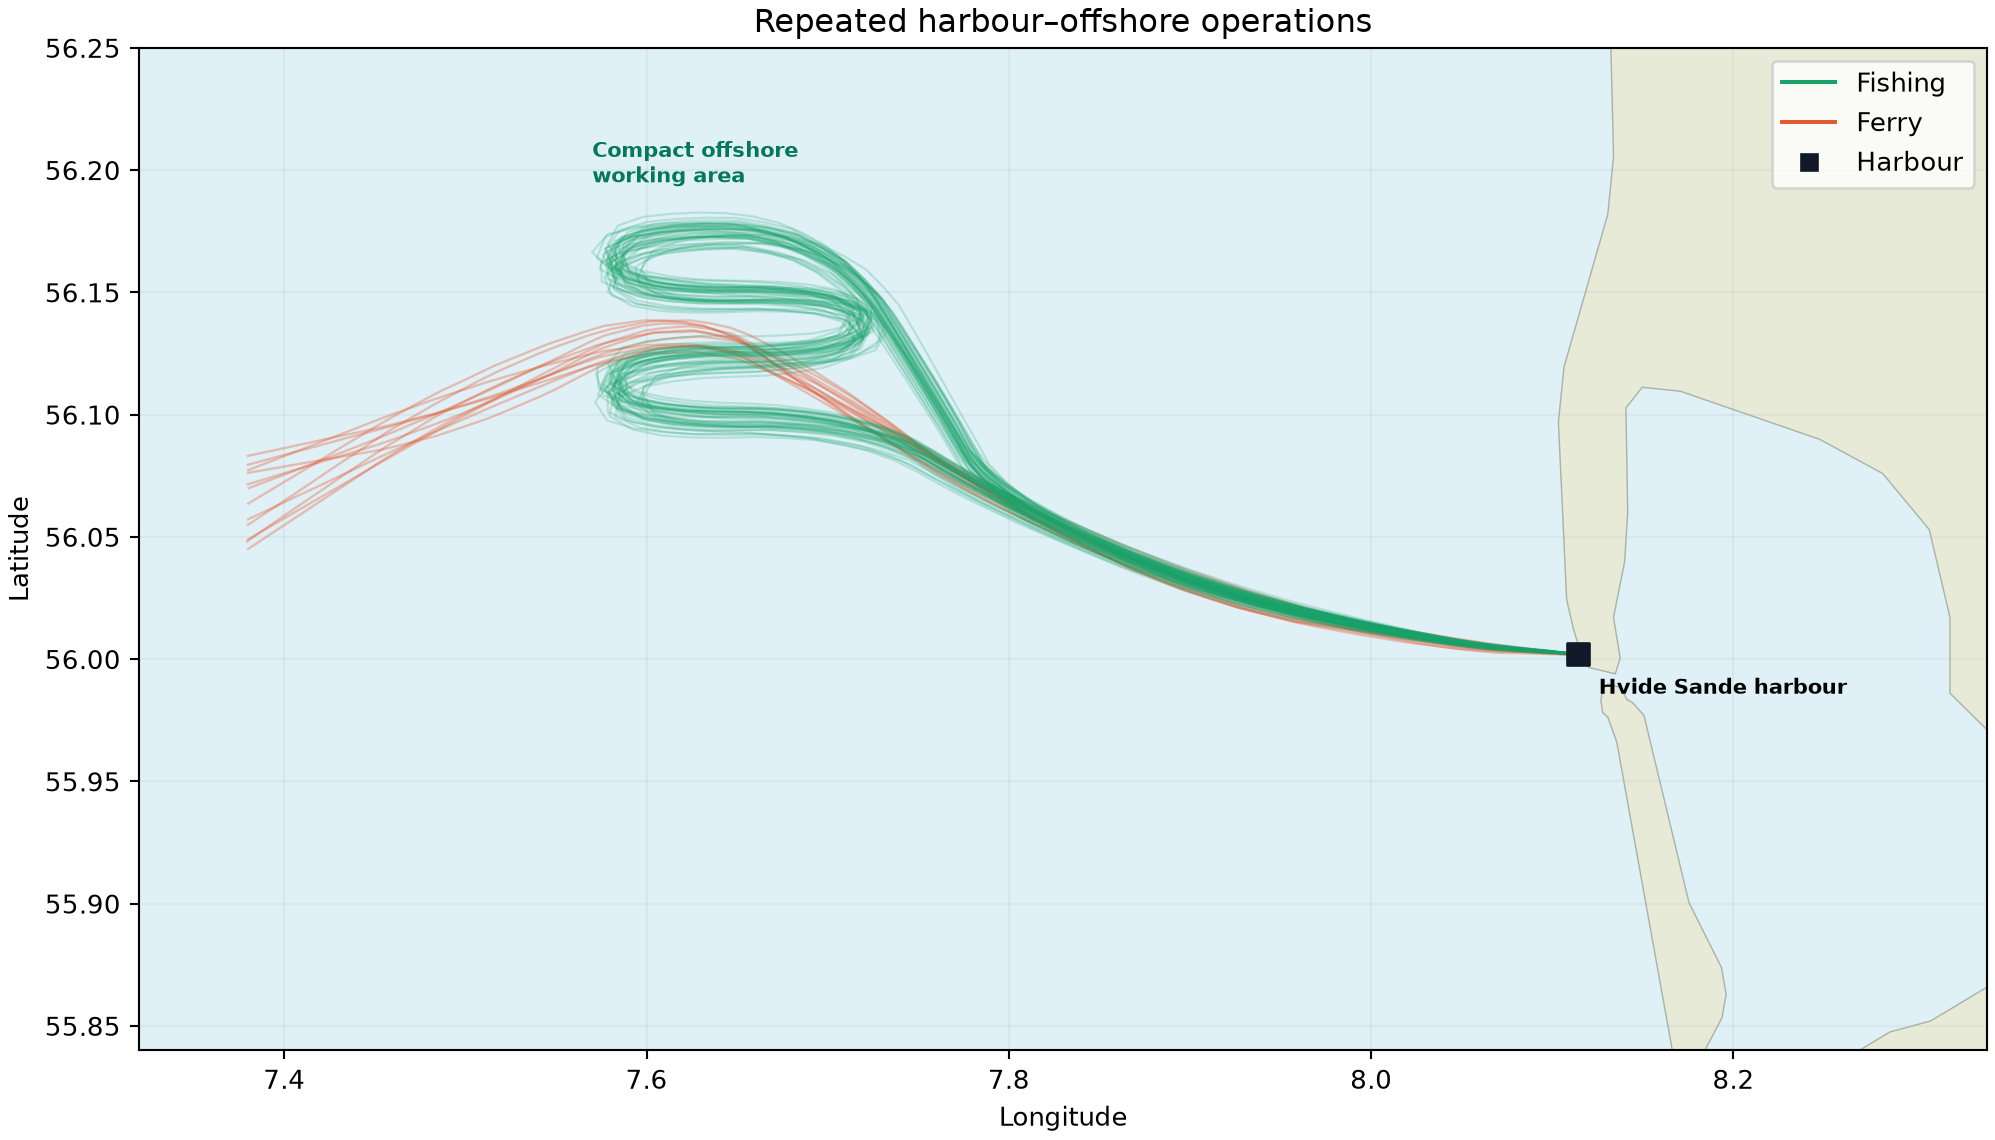

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby("vessel_id").trajectory_id.nunique())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/repeated_offshore_activity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeated_fishing_harbour_offshore",
  "insight": "A large share of the repeated offshore activity is generated by the same fishing vessel, whose voyages consistently connect the harbour with a compact offshore working area.",
  "insight_value": {
    "fishing_voyages": 40,
    "same_fishing_vessel_share": 1.0,
    "median_pairwise_path_distance_km": 0.316
  },
  "plot": {
    "plot_type": "trajectory_map",
    "title": "Repeated Harbour–Offshore Activity",
    "file": "visualizations/repeated_offshore_activity.png",
    "description": "Map the same vessel repeatedly following a similar harbour--offshore working-area--harbour path, with limited voyage-to-voyage variation."
  },
  "question": "Who generates the repeated offshore activity?",
  "actionable_insight": "Map the same vessel repeatedly following a similar harbour--offshore working-area--harbour path, with limited voyage-to-voyage variation.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby(\"vessel_id\").trajectory_id.nunique())",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "ship_type",
    "gps_position",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How does the fishing vessel alternate between transit and work?

#### Analysis action

Compare voyage-progress speed profiles and successive COG changes between harbour-transit and offshore-operation phases.

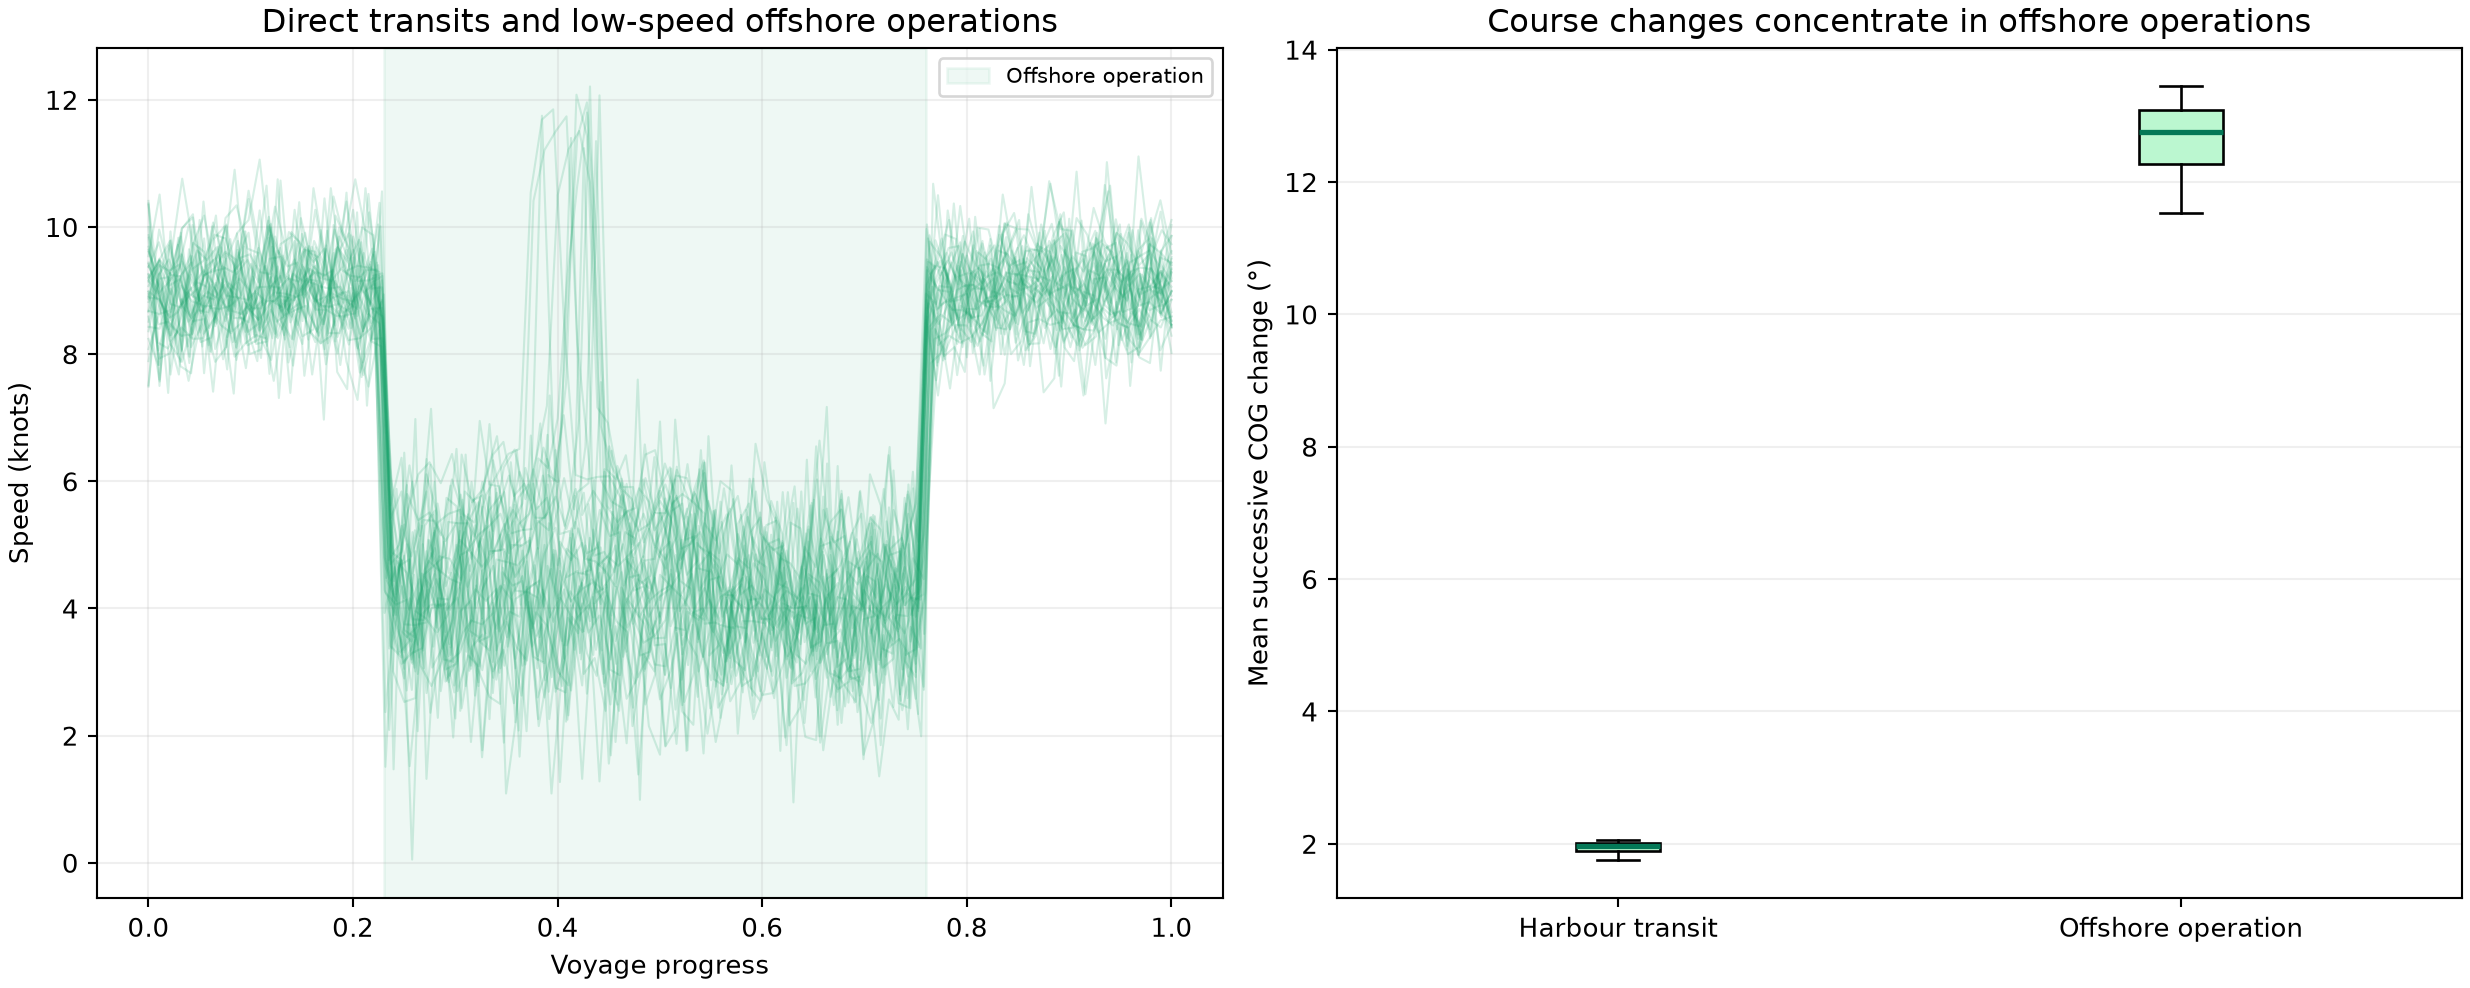

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); df["cog_change"]=abs((df.groupby("trajectory_id").cog.diff()+180)%360-180); print(df.groupby(["trajectory_id","nav_status"])[["sog_knots","cog_change"]].describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/fishing_operating_phases.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "fishing_phase_alternation",
  "insight": "The fishing vessel alternates between direct harbour transits and low-speed offshore operations before returning to the harbour.",
  "insight_value": {
    "median_under_fishing_share": 0.517
  },
  "plot": {
    "plot_type": "speed_profile_and_course_change_by_phase",
    "title": "Fishing Transit and Operating Phases",
    "file": "visualizations/fishing_operating_phases.png",
    "description": "Compare voyage-progress speed profiles and successive COG changes between harbour-transit and offshore-operation phases."
  },
  "question": "How does the fishing vessel alternate between transit and work?",
  "actionable_insight": "Compare voyage-progress speed profiles and successive COG changes between harbour-transit and offshore-operation phases.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); df[\"cog_change\"]=abs((df.groupby(\"trajectory_id\").cog.diff()+180)%360-180); print(df.groupby([\"trajectory_id\",\"nav_status\"])[[\"sog_knots\",\"cog_change\"]].describe())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "point_speed",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp",
    "navigation_status"
  ]
}

### **Question 3**: How do recurring ferry movements differ from fishing movements?

#### Analysis action

Compare trajectory frequency, within-voyage speed variation, and successive heading changes; heading consistency is measured from heading rather than COG.

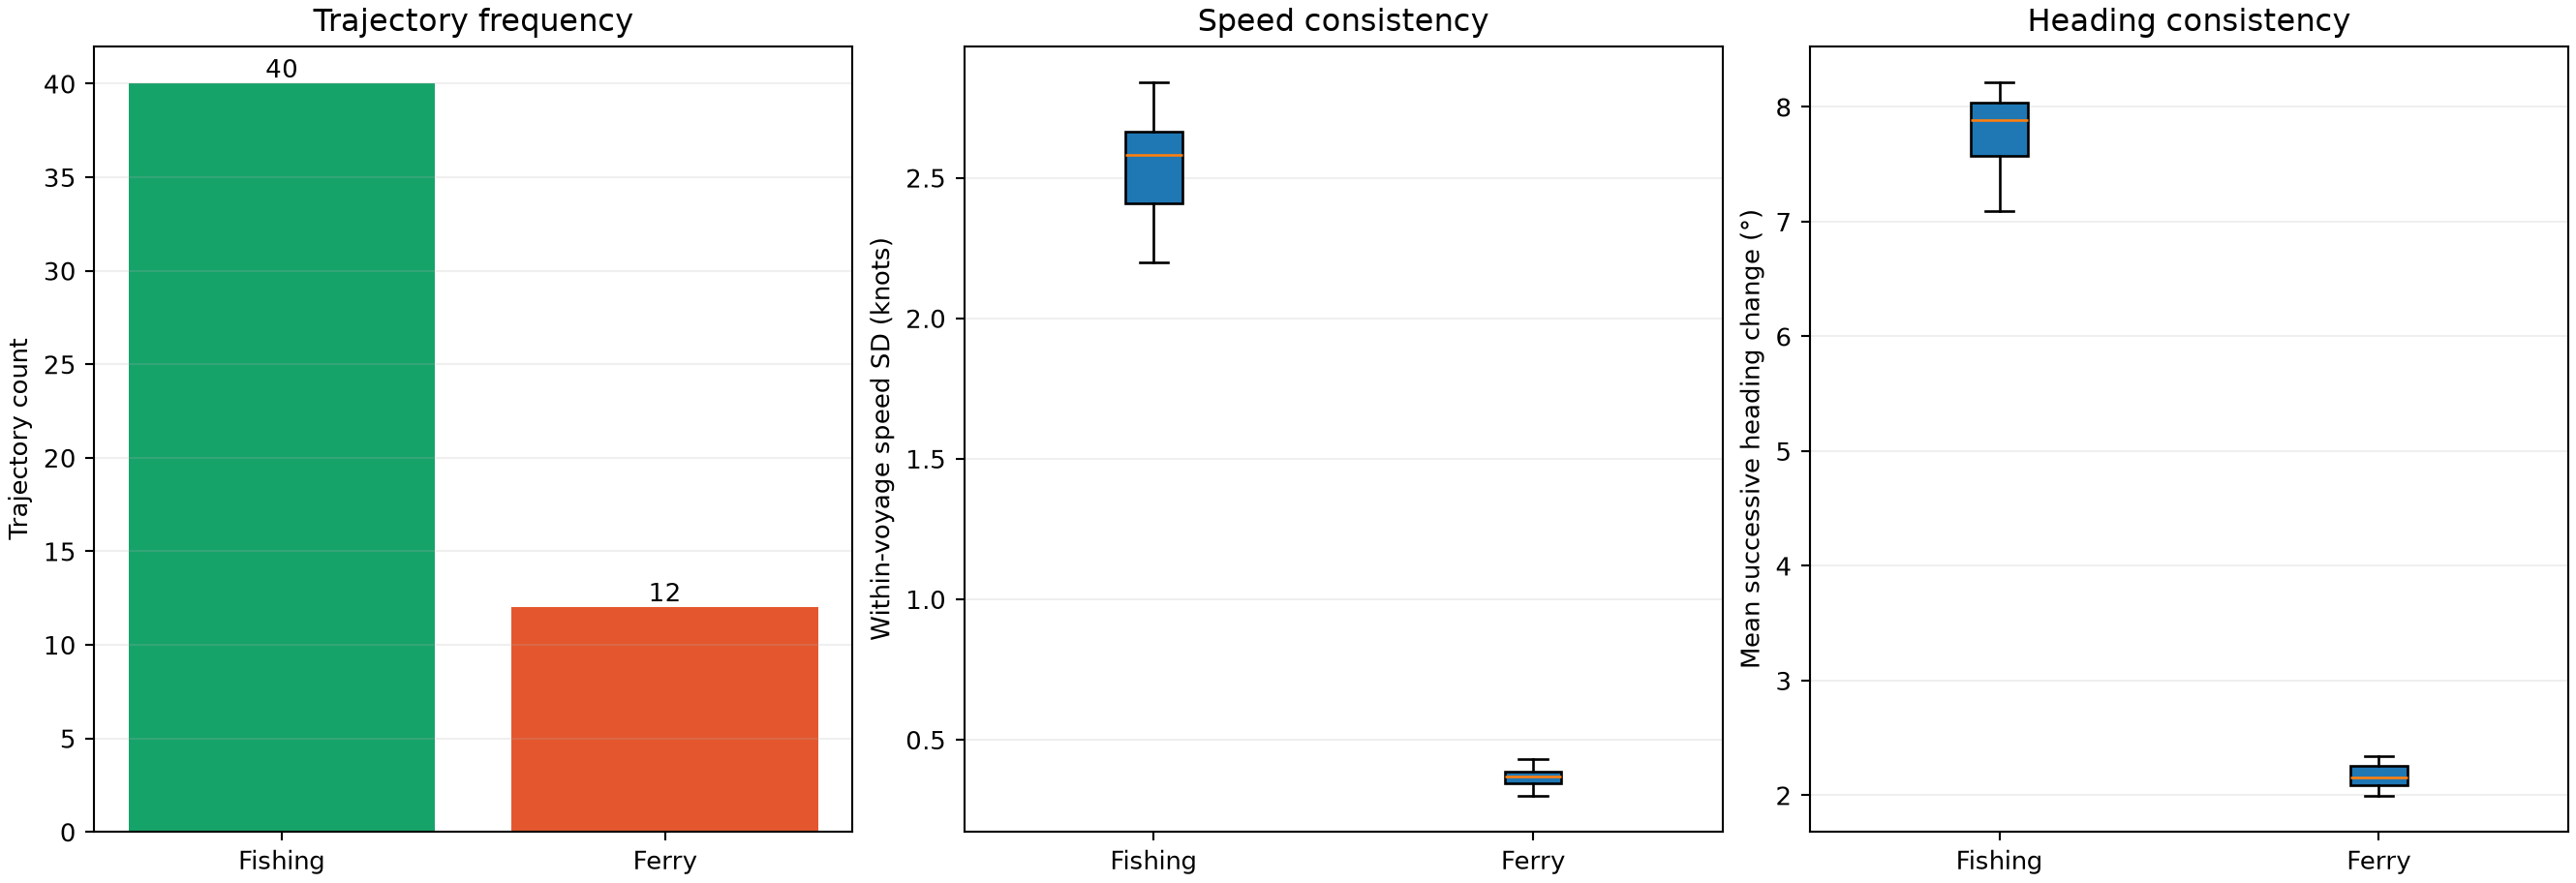

In [ ]:
import pandas as pd, numpy as np
df=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on="vessel_id"); df["heading_change"]=abs((df.groupby("trajectory_id").heading.diff()+180)%360-180); print(df.groupby("ship_type").agg(trajectories=("trajectory_id","nunique"),heading_change=("heading_change","median")))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/ferry_fishing_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "ferry_fishing_consistency_comparison",
  "insight": "There are also some ferry vessels that repeatedly travel between the harbour and offshore areas, but they are less frequent and show more consistent speed and heading patterns than the fishing vessel.",
  "insight_value": {
    "trajectory_counts": {
      "fishing": 40,
      "ferry": 12
    },
    "median_speed_sd_knots": {
      "fishing": 2.58,
      "ferry": 0.37
    },
    "median_successive_heading_change_deg": {
      "fishing": 7.89,
      "ferry": 2.16
    }
  },
  "plot": {
    "plot_type": "frequency_and_consistency_comparison",
    "title": "Fishing and Ferry Movement Consistency",
    "file": "visualizations/ferry_fishing_comparison.png",
    "description": "Compare trajectory frequency, within-voyage speed variation, and successive heading changes; heading consistency is measured from heading rather than COG."
  },
  "question": "How do recurring ferry movements differ from fishing movements?",
  "actionable_insight": "Compare trajectory frequency, within-voyage speed variation, and successive heading changes; heading consistency is measured from heading rather than COG.",
  "code": "import pandas as pd, numpy as np\ndf=pd.read_csv(dataset_path).merge(pd.read_csv(user_dataset_path),on=\"vessel_id\"); df[\"heading_change\"]=abs((df.groupby(\"trajectory_id\").heading.diff()+180)%360-180); print(df.groupby(\"ship_type\").agg(trajectories=(\"trajectory_id\",\"nunique\"),heading_change=(\"heading_change\",\"median\")))",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "point_speed",
    "heading",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 4**: How does the fishing vessel respond when it approaches a ferry?

#### Analysis action

Use a close-range view and distance-band summary to show the pronounced speed increase and engine-status transition within one kilometre of a synchronized ferry position.

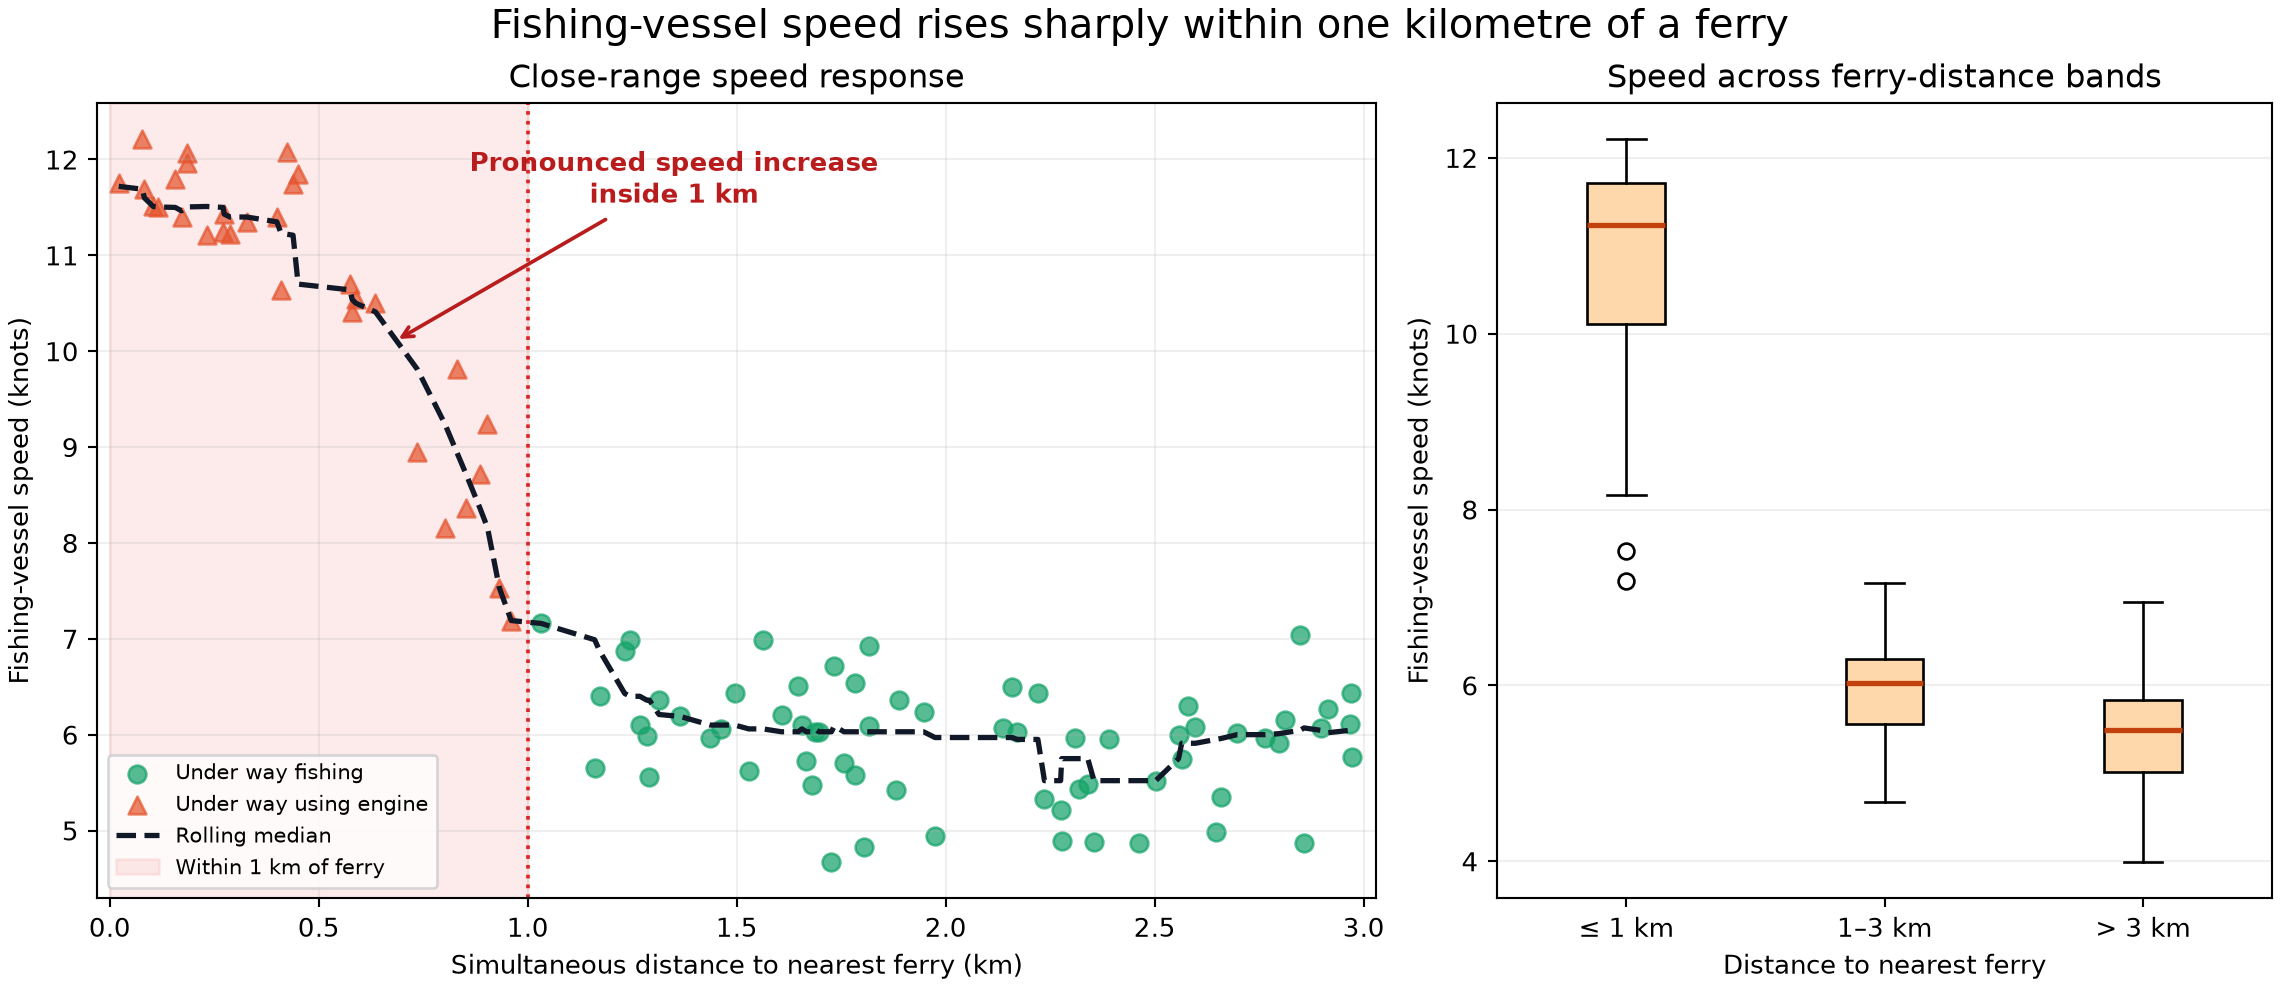

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); encounters=df[df.trajectory_id.str.startswith("fishing_voyage_")]; print(encounters.groupby("nav_status").sog_knots.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/ferry_approach_response.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "fishing_response_to_ferry_approach",
  "insight": "When the fishing vessel approaches ferry vessels, it tends to increase speed to move away quickly and changes its status from under way fishing to under way using engine.",
  "insight_value": {
    "encounter_voyages": 12,
    "total_fishing_voyages": 40,
    "encounter_share": 0.3,
    "closest_same_time_distance_km": 0.135,
    "response_distance_threshold_km": 1.0,
    "median_speed_knots": {
      "outside_1km": 5.56,
      "within_1km": 11.24
    },
    "speed_by_simultaneous_ferry_distance_km": {
      "at_most_1km": 11.24,
      "one_to_3km": 6.03,
      "over_3km": 5.49
    },
    "engine_status_share_within_1km": 1.0
  },
  "plot": {
    "plot_type": "close_range_distance_speed_status",
    "title": "Fishing-vessel Response Near Ferries",
    "file": "visualizations/ferry_approach_response.png",
    "description": "Use a close-range view and distance-band summary to show the pronounced speed increase and engine-status transition within one kilometre of a synchronized ferry position."
  },
  "question": "How does the fishing vessel respond when it approaches a ferry?",
  "actionable_insight": "Use a close-range view and distance-band summary to show the pronounced speed increase and engine-status transition within one kilometre of a synchronized ferry position.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); encounters=df[df.trajectory_id.str.startswith(\"fishing_voyage_\")]; print(encounters.groupby(\"nav_status\").sog_knots.describe())",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "trajectory_timestamp",
    "gps_position",
    "point_speed",
    "navigation_status",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 19)

A large share of the repeated offshore activity is generated by the same fishing vessel, whose voyages consistently connect the harbour with a compact offshore working area. The fishing vessel alternates between direct harbour transits and low-speed offshore operations before returning to the harbour. There are also some ferry vessels that repeatedly travel between the harbour and offshore areas, but they are less frequent and show more consistent speed and heading patterns than the fishing vessel. When the fishing vessel approaches ferry vessels, it tends to increase speed to move away quickly and changes its status from under way fishing to under way using engine.